In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [3]:
# Notation
# x = position
# v = velocity
# a = acceleration
# R = Random number following Gaussian distribution

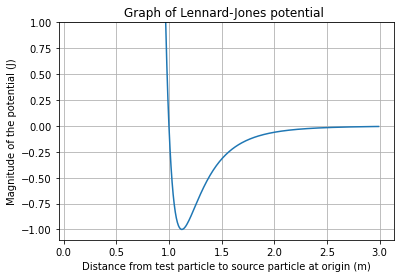

In [4]:
# Graph of the Lennard-Jones potential
x = np.arange(0.1, 3, 0.01)
y = 4*(1/x**12 - 1/x**6)
plt.plot(x,y)
plt.ylim(-1.1,1)
plt.grid(True)
plt.title("Graph of Lennard-Jones potential ")

plt.xlabel("Distance from test particle to source particle at origin (m)")
plt.ylabel("Magnitude of the potential (J)")
plt.savefig("Lennard-Jones", dpi=100)

#### (a) Model the particle motion starting from x(0) = 3 with timestep ∆t = 0.001 for at least 100,000 steps. Record the positions and velocities at every 10th step.


In [5]:
# sigma = m = epsilon = 1
timespan = 0.001

# Derivative of Lennard-Jones potential
def U_prime(x):
    return 4*(-12/x**13 + 6/x**7)

In [6]:
# Initial conditions
x_old = 3
v_old = 0
a_old = 0
timespan = 0.001


# Use a small gamma for now
gamma = 0.00

i = 1

# Lists for recording x and v.
recorded_x = []
recorded_v = []

# Repeating algorithm 100000 times
while i < 500001:
    
    # Random gaussian number
    R = np.random.normal(0,1)
    
    # Velocity Verlet algorithm:
    x_new = x_old + v_old * timespan + 1/2 * a_old * (timespan)**2
    
    v_new = ( 2 * v_old/timespan + a_old - U_prime(x_new) + np.sqrt(2*gamma)*R )/(2/timespan + gamma)
    
    a_new = 2/timespan*((2*v_old/timespan + a_old - U_prime(x_new) + np.sqrt(2*gamma)* R)/( 2/timespan + gamma)-v_old) - a_old
    
    
# Recording position and velocity every 10th step
    if i % 10 == 0:
        recorded_x = np.append(recorded_x, x_new)
        recorded_v = np.append(recorded_v, v_new)
    
    # Update new x and v coordinates
    x_old = x_new
    v_old = v_new
    
    i += 1

KeyboardInterrupt: 

#### (b) Calculate the position and velocity distribution histograms and normalise them by requiring that the area under the curve is equal to 1. If the histograms are not smooth, increase the number of steps.


In [ ]:
plt.figure(figsize = (8,6))
sns.histplot(recorded_x, stat = "density", bins = np.arange(0.9,3.15,0.05))

plt.title("Position distribution histogram")
plt.xlabel("Distance x of particle from the origin")
plt.ylabel("Density");

In [ ]:
plt.figure(figsize = (8,6))
sns.histplot(recorded_v, stat = "density", bins=np.arange(-1,1.05,0.05))

plt.title("Velocity distribution histogram")
plt.xlabel("Velocity of particle")
plt.ylabel("Density");

#### (c) Calculate the average velocity and the temperature from the equipartition theorem and discuss the relation between the observed temperature and the input one.


In [ ]:
v_avg = sum(abs(recorded_v)) / len(recorded_v)
print(len(recorded_x), len(recorded_v))

In [ ]:
# Kinetic energy = f/2 * k_b * T = 1/2 m * v^2
# f = 1, m = 1, k_b T = 1 
Kinetic_energy = 1/2 * (1) * v_avg**2

T = 2/(1) * Kinetic_energy
print(T)



#### (d) Calculate the potential of mean force: UPMF = −kBT ln(1 + h(r)), where h(r) is the position distribution function, and compare it to the Lennard-Jones potential

To calculate the potential of the mean force, the position distribution function h(r) needs to be defined. 

To define this, the heights of the bars in the position distribution histogram are needed. Each bar is accessed using `histplot().patches` and the bar's height attribute is accessed using `bar.get_height()`. The height of each bar is stored into x_heights using a list comprehension.

In [ ]:
x_heights = [bar.get_height()for bar in sns.histplot(recorded_x, stat = "density", bins = np.arange(0.9,3.15,0.05)).patches];
x_heights = np.array(x_heights)

To check that x_heights stores the right values, recall that the area under the curve of the histogram equals 1. Therefore the sum of all elements of x_heights, multiplied by the width of the bins, 0.05, should equal 1:

In [ ]:
sum(x_heights) * 0.05
# Correct to machine precision

In [ ]:
# x_heights is now turned into a pandas series so the x positions, and their relative probabilities can be collected together

x_heights_series = pd.Series(x_heights*0.05, index = np.arange(0.9, 3.10, 0.05)) 

Define h(r) as the probability that the particle is between r and r+dr away from the other particle at the origin. Therefore r = x, the position of the particle away from the origin. The probability to get an x value between 1.5 and 1.55 for instance, is the area of the 1.5 to 1.55 bin in the position distribution histogram. To get this area, just multiply the height of the 1.5 to 1.55 bin by its width, 0.05.

In [ ]:
# Defining h(r) = h(x):
def h(x):
    return(x_heights_series[x]) # returns the probability associated with the position x away from the origin.
                                # Only works for values of x with x mod 0.05 = 0 between 0 and 4.

In [ ]:
def Upmf(x):
    return -np.log(1 + h(x))

In [ ]:
plt.figure(figsize = (8,8))
x = np.arange(0.9, 3.10, 0.05)
plt.plot(x, Upmf(x), "o")

y = np.arange(1,3.15,0.001)
LennardJones = 4*(1/y**12 - 1/y**6)
plt.plot(y, LennardJones)
#plt.ylim(-1.5,0.5)
plt.ylabel("Potential magnitude")
plt.xlabel("distance x from origin")
plt.title("Comparison plot of Lennard-Jones potential and potential of the mean force")
plt.legend(["Potential of the mean force","Lennard-Jones potential"]);